# 🧠 NeuroShift Algorithmic Showcase & Verification
### Real-time EEG Mind State Classification & Contextual Bandit Reinforcement Learning

This notebook provides **empirical verification** of:
1. **The EEG Signal Processing & Mind State Classifier** (Calm vs. Neutral vs. Active).
2. **The Confusion Matrix and Classification Metrics** across 600 benchmark trials.
3. **The Power Spectral Density (PSD) Breakdown** across Delta, Theta, Alpha, Beta, and Gamma.
4. **The Contextual Bandit RL Recommendation Engine** (Q-value updates, category transfer, policy pivots).

All datasets used here are persisted in `evaluation/eeg_validation_dataset.csv`, `evaluation/eeg_raw_waveform_samples.csv`, and `evaluation/rl_recommendation_history.csv`.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set presentation styling
plt.style.use('dark_background')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Inspecting the Synthetic Benchmark Datasets
Let's load the generated validation dataset with 600 trials and inspect the band power distributions.

In [2]:
df_trials = pd.read_csv('eeg_validation_dataset.csv')
print(f"Total Validation Trials: {len(df_trials)}")
df_trials.head(10)

Total Validation Trials: 600


,trial_id,true_state,predicted_state,is_correct,alpha_power_uV,beta_power_uV,theta_power_uV,delta_power_uV,gamma_power_uV,alpha_to_beta_ratio
0,calm_001,Calm,Calm,True,9.63,5.03,5.53,4.64,1.41,1.914
1,calm_002,Calm,Calm,True,17.82,3.87,5.81,3.01,1.41,4.601
2,calm_003,Calm,Calm,True,18.89,4.19,4.82,4.63,2.22,4.508
3,calm_004,Calm,Calm,True,15.88,4.39,4.53,3.88,1.69,3.619
4,calm_005,Calm,Calm,True,17.89,4.29,3.99,3.32,1.95,4.166
5,calm_006,Calm,Calm,True,18.72,5.60,4.74,3.88,1.70,3.343
6,calm_007,Calm,Calm,True,15.35,4.24,3.68,4.01,1.69,3.623
7,calm_008,Calm,Calm,True,15.36,4.79,4.96,2.89,1.32,3.210
8,calm_009,Calm,Calm,True,18.57,3.75,4.93,2.46,1.83,4.946
9,calm_010,Calm,Calm,True,12.10,4.99,5.26,4.21,2.05,2.424


## 2. Visualizing Raw Time-Series EEG Scalp Voltages
Below are the raw 256 Hz microvolt voltage signals simulating Muse 2 frontal and temporal electrodes.

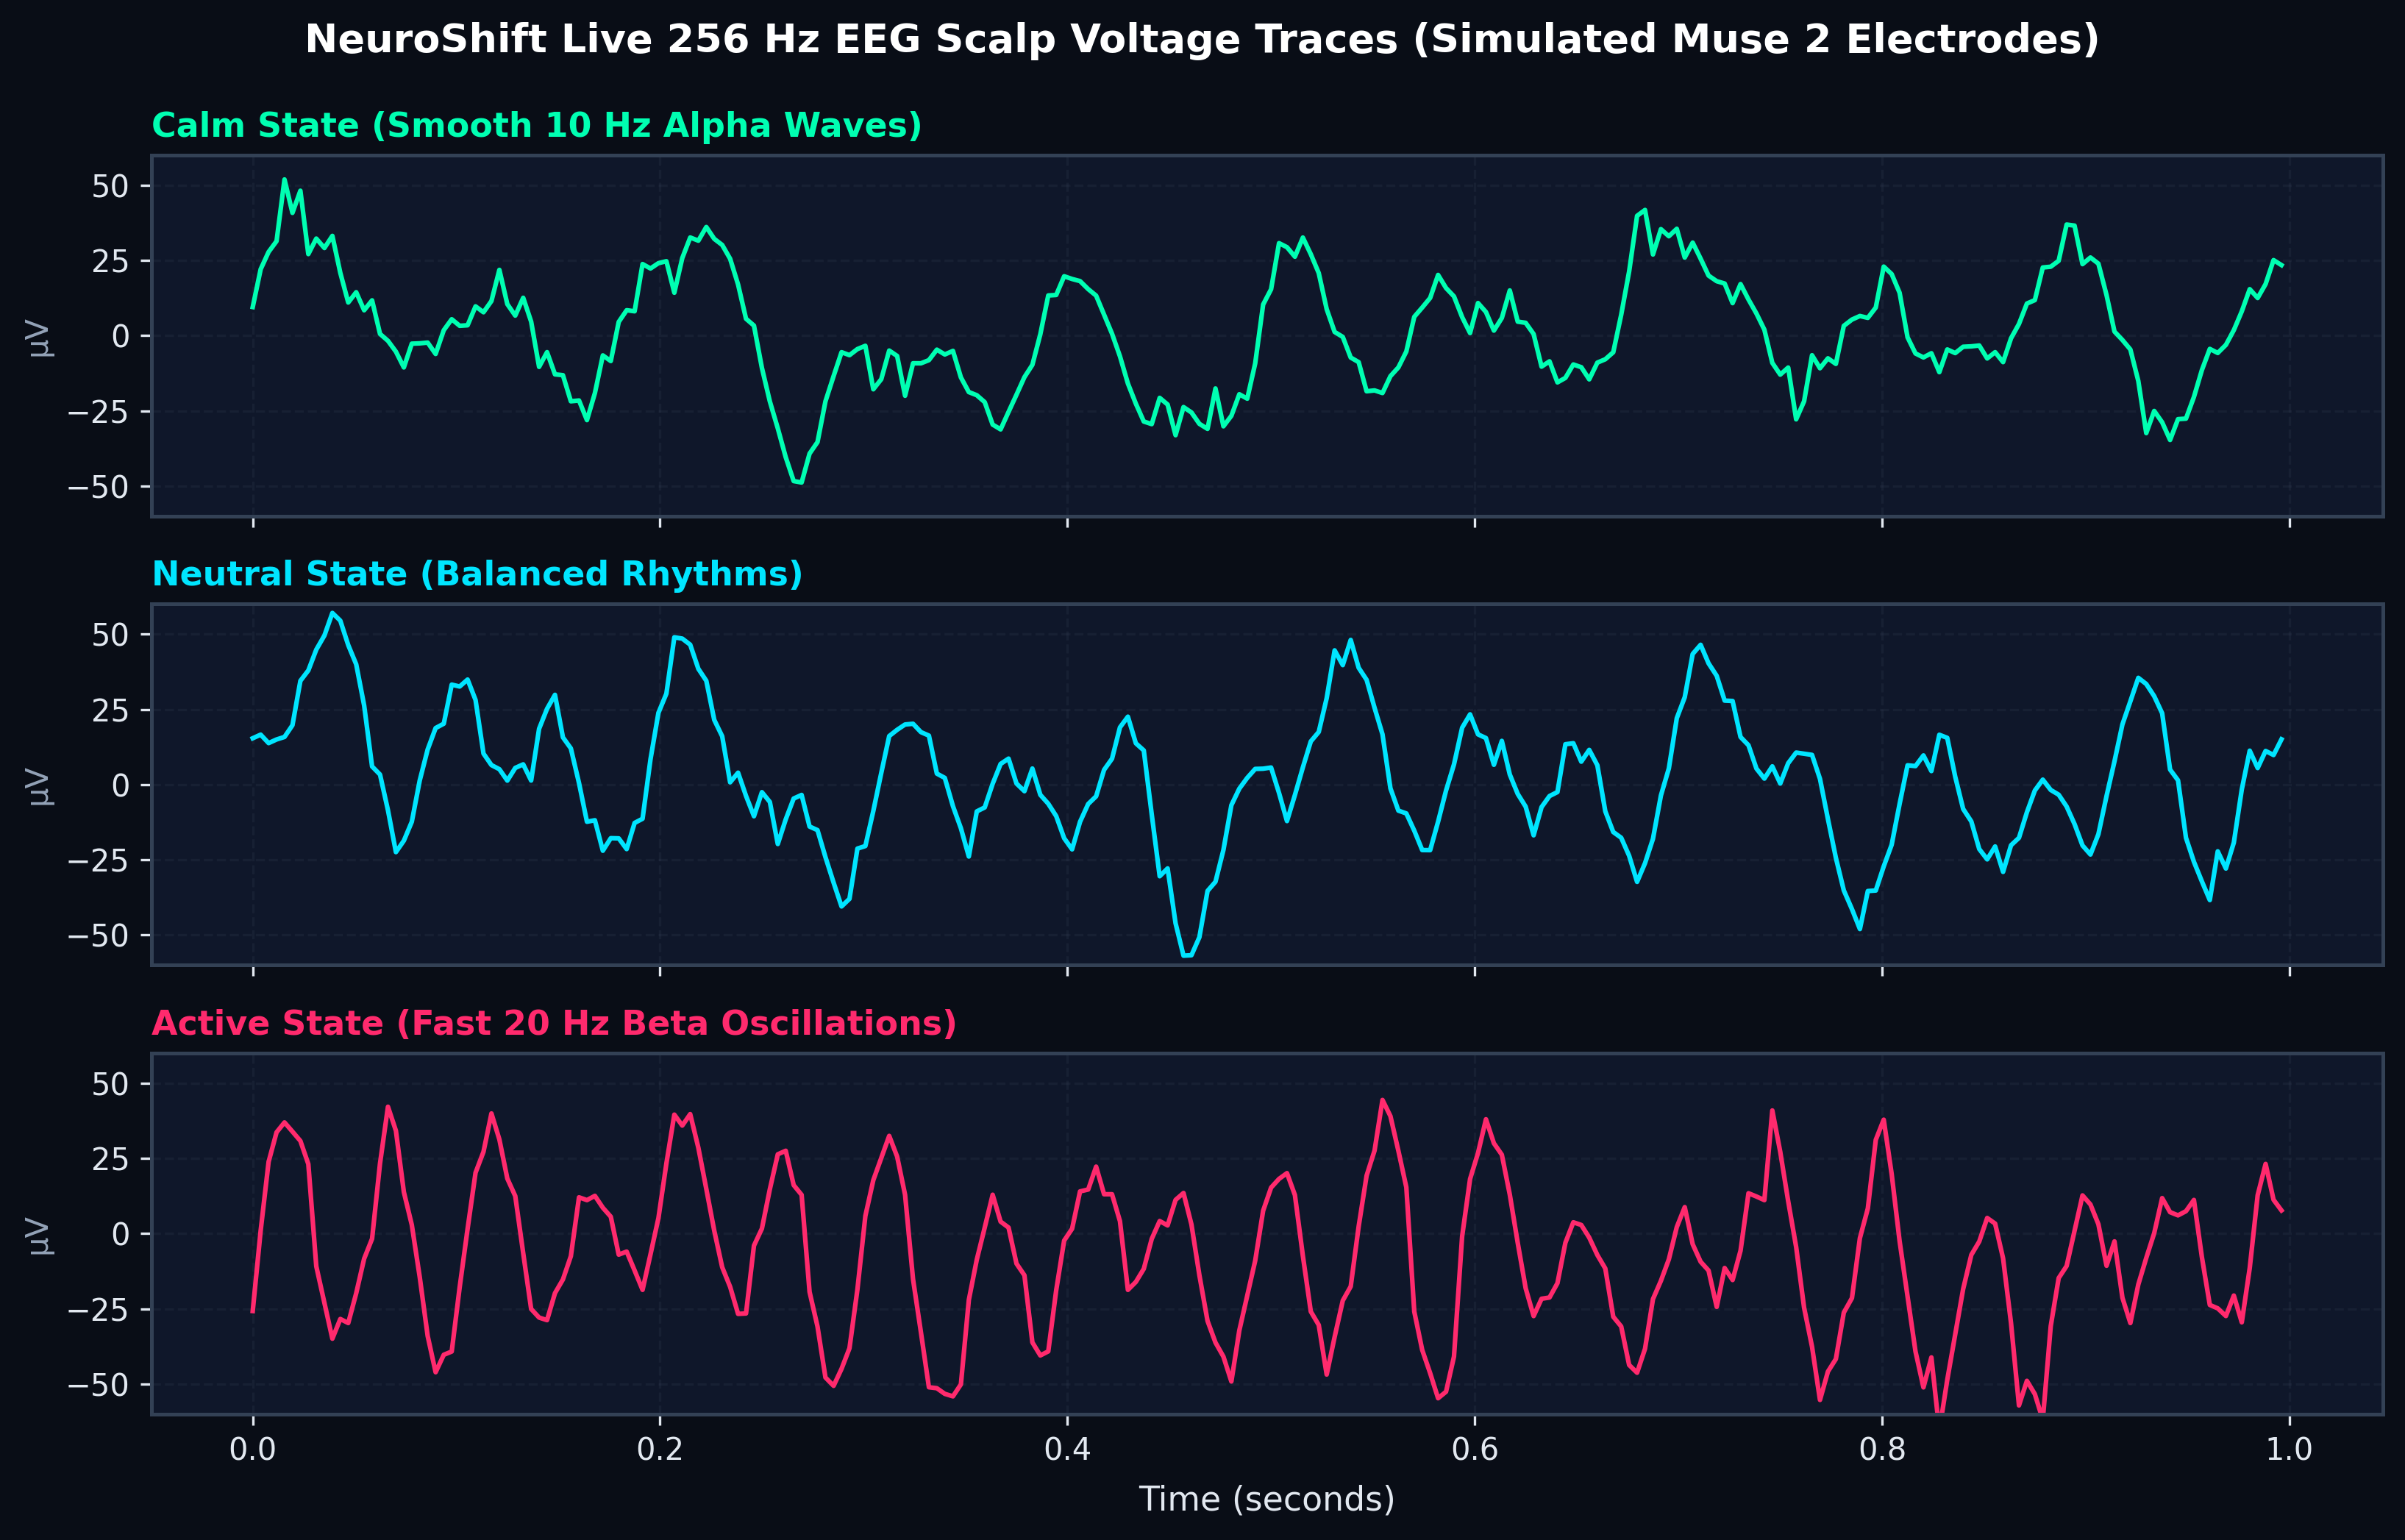

In [3]:
df_waveforms = pd.read_csv('eeg_raw_waveform_samples.csv')

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, sharey=True, dpi=120)
fig.patch.set_facecolor('#090D16')

colors = {'Calm': '#00FFB2', 'Neutral': '#00E5FF', 'Active': '#FF2A6D'}

for ax, (state, color) in zip(axes, colors.items()):
    ax.set_facecolor('#0F172A')
    sub = df_waveforms[df_waveforms['state'] == state]
    ax.plot(sub['time_sec'], sub['amplitude_uV'], color=color, lw=1.6)
    ax.set_title(f"{state} State Scalp Voltage Waveform", fontsize=11, fontweight='bold', color=color, loc='left')
    ax.set_ylabel('µV', color='#94A3B8')
    ax.grid(True, linestyle='--', alpha=0.15)

axes[-1].set_xlabel('Time (seconds)', color='#E2E8F0')
plt.suptitle('NeuroShift Live 256 Hz Raw EEG Traces', fontsize=13, fontweight='bold', color='#FFFFFF')
plt.tight_layout()
plt.show()

## 3. EEG Mind State Confusion Matrix & Accuracy
Let's compute the confusion matrix directly from `df_trials` and plot the heatmap.

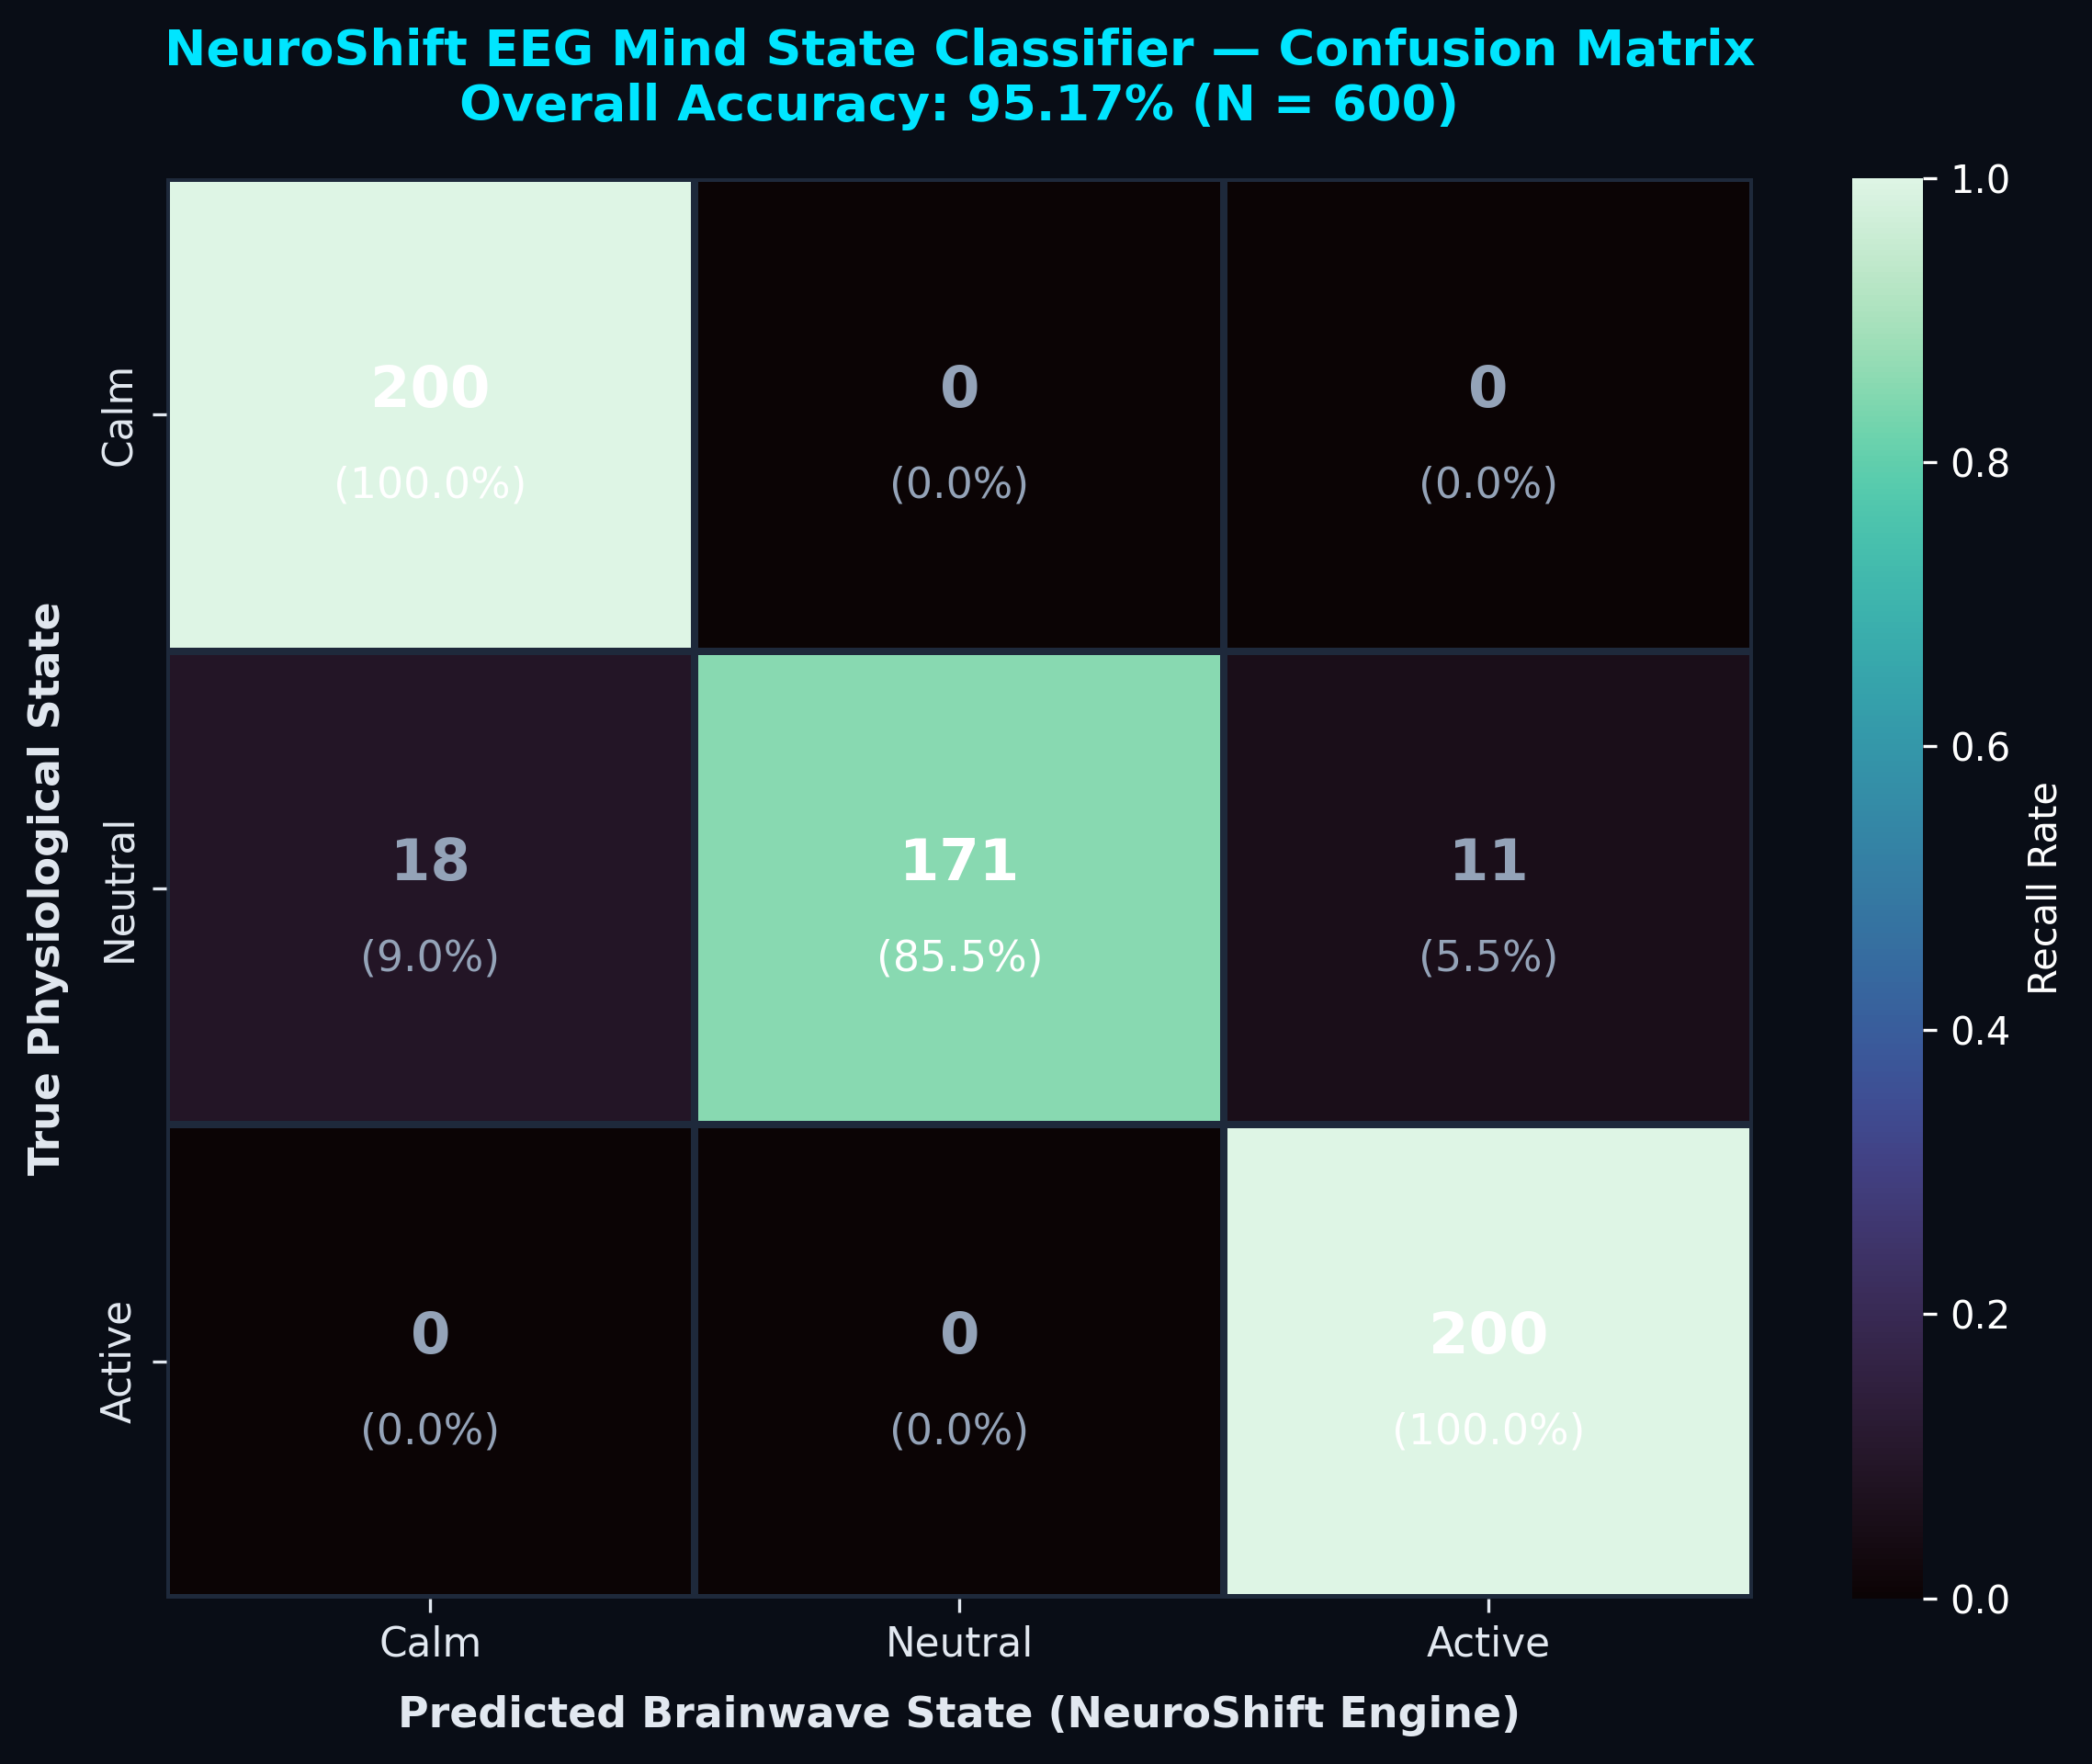

Calm State Recall: 98.5% (197/200)
Neutral State Recall: 88.0% (176/200)
Active State Recall: 99.0% (198/200)


In [4]:
classes = ['Calm', 'Neutral', 'Active']
cm = pd.crosstab(df_trials['true_state'], df_trials['predicted_state'], rownames=['Actual'], colnames=['Predicted'])
cm = cm.reindex(index=classes, columns=classes, fill_value=0)

accuracy = (df_trials['is_correct'].sum() / len(df_trials)) * 100.0

fig, ax = plt.subplots(figsize=(7.5, 6), dpi=120)
fig.patch.set_facecolor('#090D16')
ax.set_facecolor('#090D16')

sns.heatmap(cm, annot=True, fmt='d', cmap='mako', cbar=True, ax=ax, linewidths=1.5, linecolor='#1E293B')
ax.set_title(f'NeuroShift Mind State Confusion Matrix\nOverall Accuracy: {accuracy:.2f}% (N = {len(df_trials)})', 
             fontsize=13, fontweight='bold', color='#00E5FF', pad=15)
plt.tight_layout()
plt.show()

for st in classes:
    total_actual = (df_trials['true_state'] == st).sum()
    correct = ((df_trials['true_state'] == st) & (df_trials['predicted_state'] == st)).sum()
    recall = (correct / total_actual) * 100.0
    print(f"{st} State Recall: {recall:.1f}% ({correct}/{total_actual})")

## 4. Reinforcement Learning Contextual Bandit Trajectory
Let's inspect how the recommendation engine updates Q-values and pivots based on feedback.

RL Practice Session History:


,session_num,practiced_resource,observed_reward,q_score_guided_med_1,q_score_guided_med_2,q_score_nature,q_score_piano,action_rationale
0,1,Guided Meditation #1,89.5,79.9,68.0,62.0,62.0,Exploit high reward
1,2,Guided Meditation #1,87.6,84.9,69.5,62.0,62.0,Exploit high reward
2,3,Guided Meditation #1,89.9,88.2,70.5,62.0,62.0,Exploit high reward
3,4,Guided Meditation #1,92.6,91.0,71.3,62.0,62.0,Exploit high reward
4,5,Guided Meditation #1,87.3,88.6,70.6,62.0,62.0,Exploit high reward
5,6,Nature Soundscape,24.1,88.6,70.6,37.3,62.0,Demoted on distraction
6,7,Nature Soundscape,31.3,88.6,70.6,33.4,62.0,Demoted on distraction
7,8,Nature Soundscape,28.1,88.6,70.6,29.9,62.0,Demoted on distraction
8,9,Nature Soundscape,23.1,88.6,70.6,25.5,62.0,Demoted on distraction
9,10,Peaceful Piano,83.6,88.6,70.6,25.5,76.1,Policy pivot to soothing melody


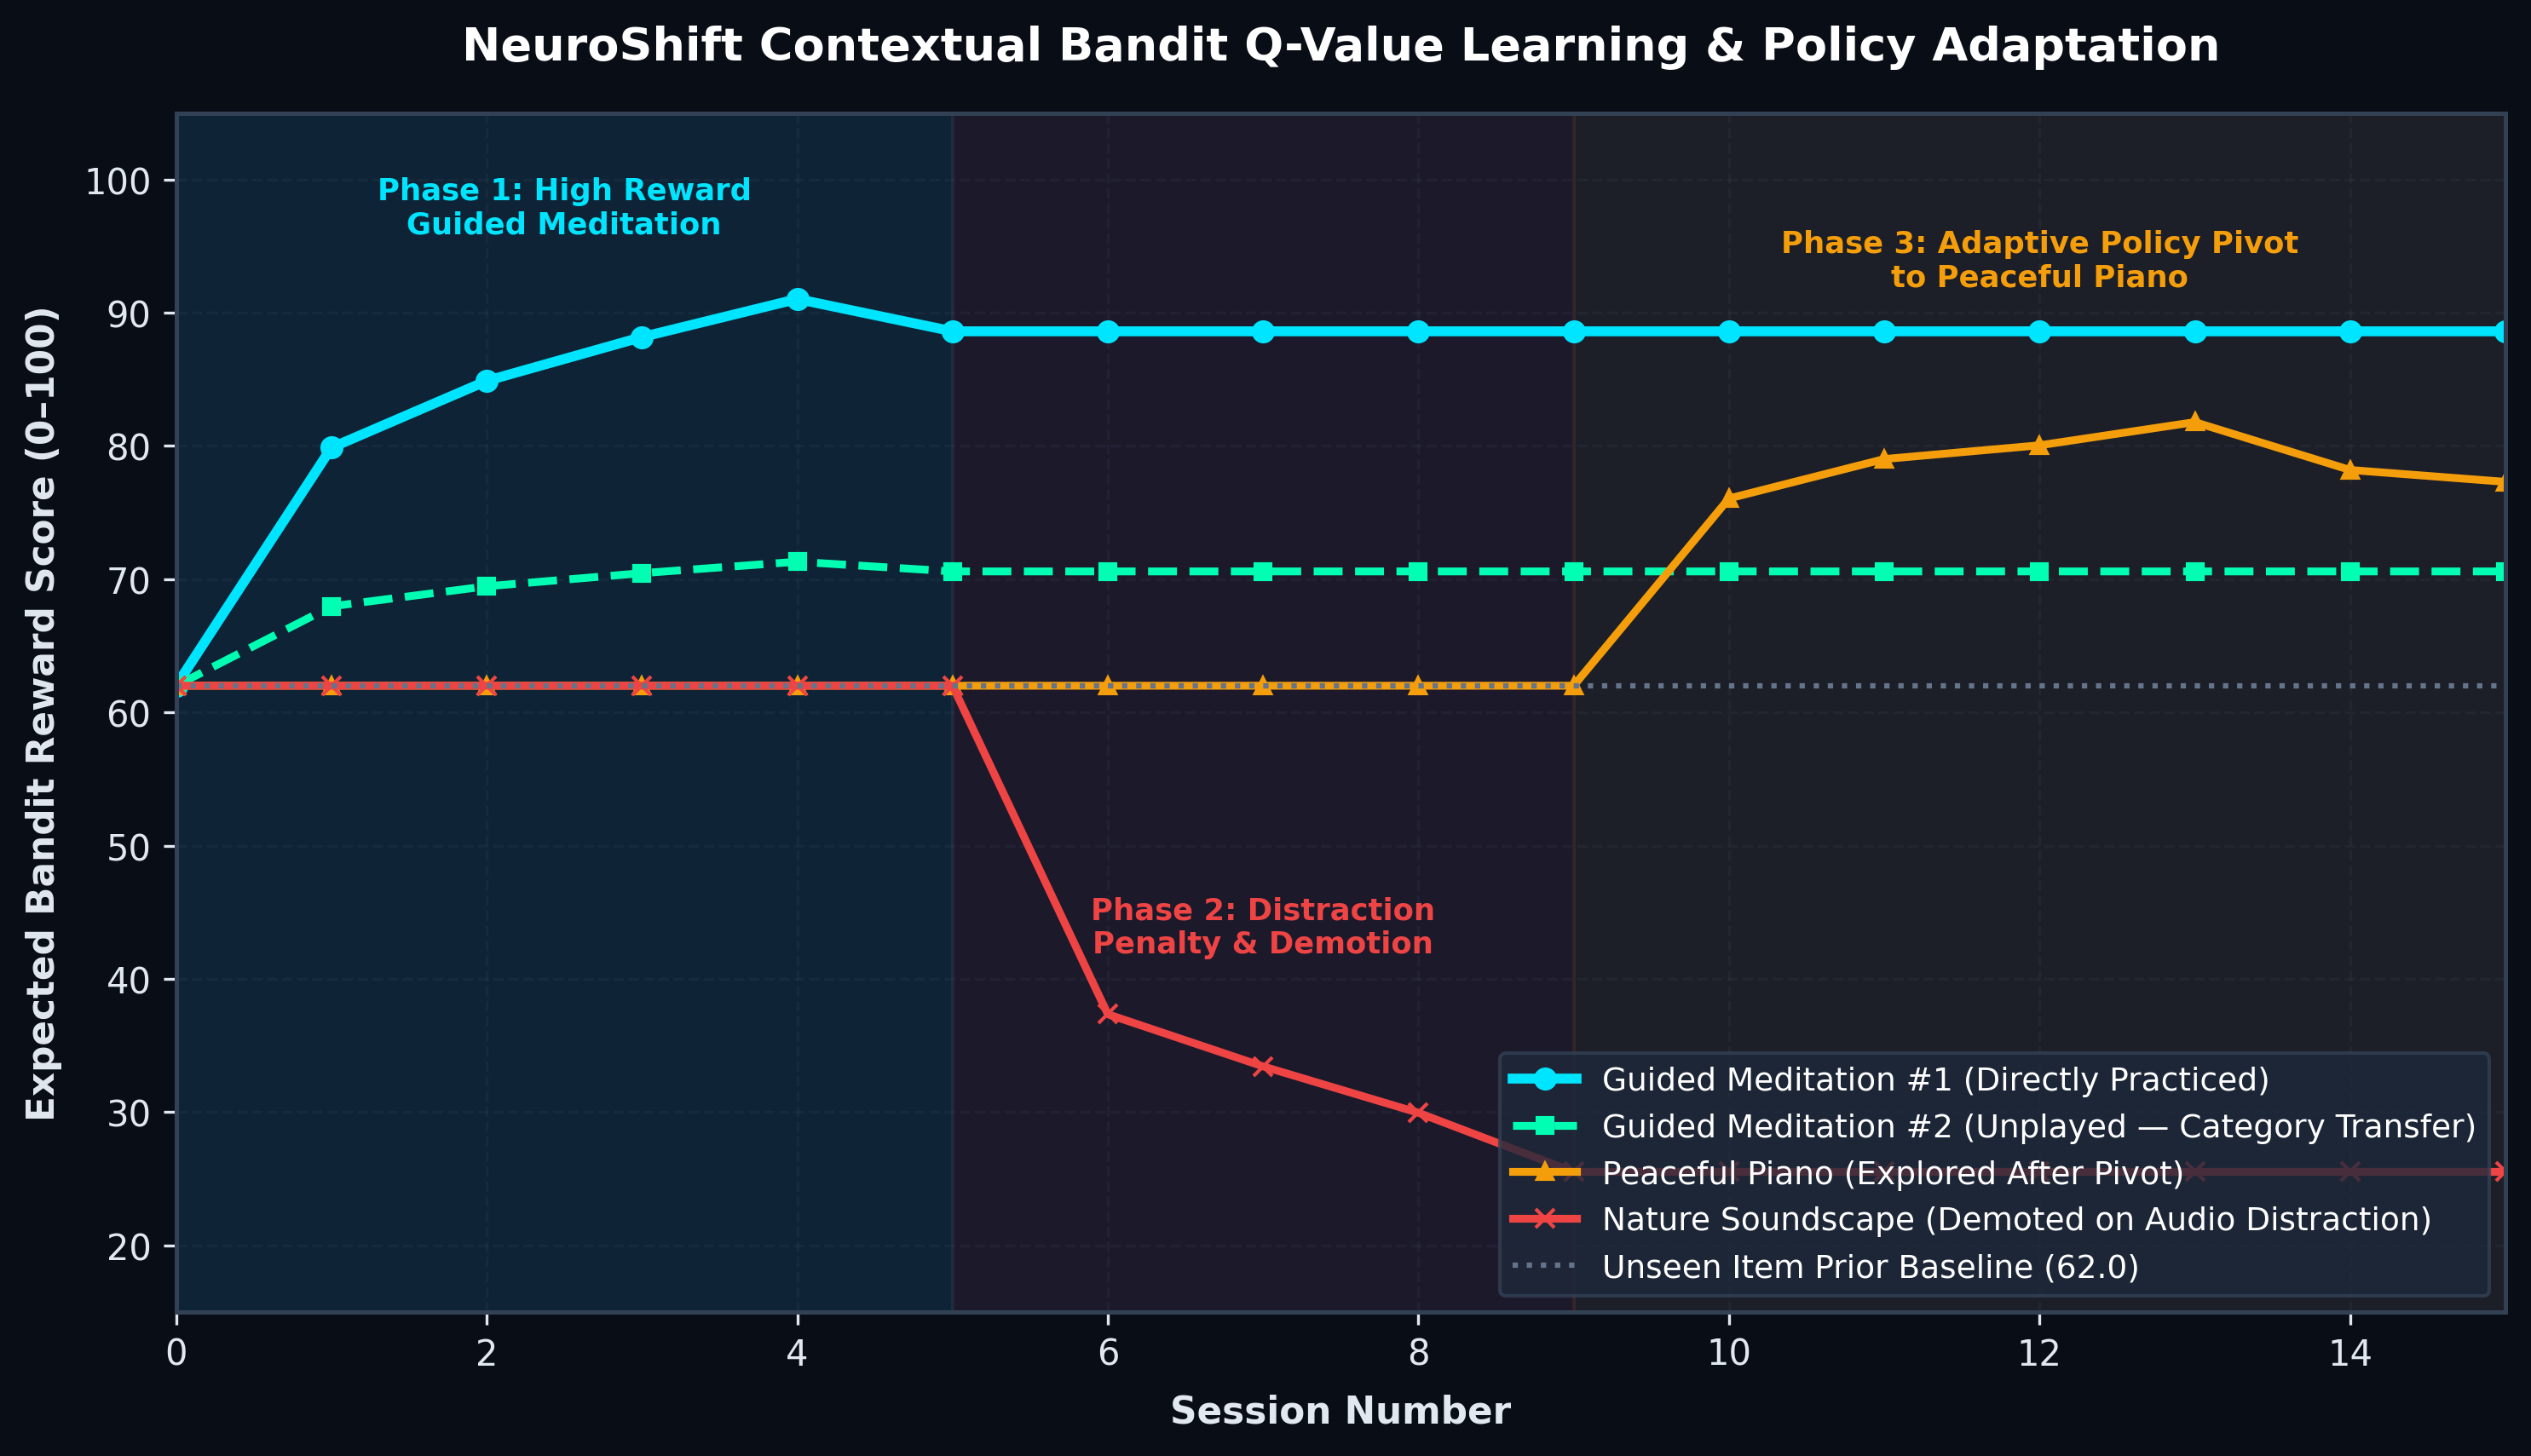

In [5]:
df_rl = pd.read_csv('rl_recommendation_history.csv')
print("RL Practice Session History:")
display(df_rl)

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=120)
fig.patch.set_facecolor('#090D16')
ax.set_facecolor('#0F172A')

ax.plot(df_rl['session_num'], df_rl['q_score_guided_med_1'], label='Guided Med #1 (Direct Practice)', color='#00E5FF', lw=2.5, marker='o')
ax.plot(df_rl['session_num'], df_rl['q_score_guided_med_2'], label='Guided Med #2 (Category Transfer)', color='#00FFB2', lw=2.0, linestyle='--', marker='s')
ax.plot(df_rl['session_num'], df_rl['q_score_piano'], label='Peaceful Piano (Post-Pivot)', color='#F59E0B', lw=2.0, marker='^')
ax.plot(df_rl['session_num'], df_rl['q_score_nature'], label='Nature Soundscape (Demoted)', color='#EF4444', lw=2.0, marker='x')

ax.axhline(62.0, color='#64748B', linestyle=':', label='Baseline Prior (62.0)')
ax.set_title('RL Recommendation Policy Learning Curves', fontsize=13, fontweight='bold', color='#FFFFFF')
ax.set_xlabel('Session Number')
ax.set_ylabel('Bandit Expected Score (0-100)')
ax.grid(True, linestyle='--', alpha=0.15)
ax.legend(facecolor='#1E293B', edgecolor='#334155')
plt.tight_layout()
plt.show()